## 1、基本理解

### 1.1 什么是长期记忆

短期记忆记录的是**会话级别（线程，Thread）**的数据， 会话间不共享。而长期记忆记录的是用户特定或应用级别的数据，任何会话都可以随时访问。

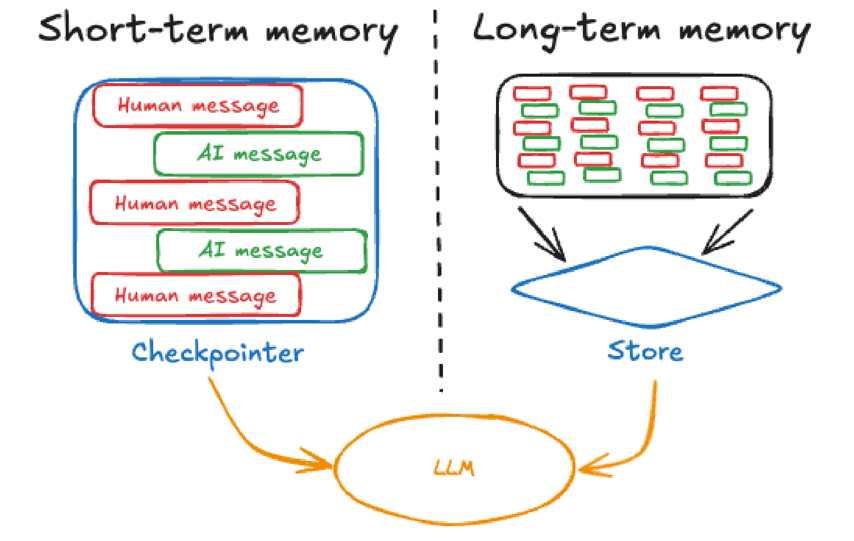

比如：
- 你喜欢简短回答
- 你偏好 Python
- 某个用户是 VIP
- 某个流程过去怎么做效果更好

这类信息不属于某一条聊天，而属于“用户/组织/应用本身”。

### 1.2 类型划分

LangChain参考[CoALA paper](https://arxiv.org/pdf/2309.02427)将长期记忆划分为三类：

| Memory Type    | 存什么    |
|----------------|--------|
| [Semantic](https://docs.langchain.com/oss/python/concepts/memory#semantic-memory)   | 事实     |
| [Episodic](https://docs.langchain.com/oss/python/concepts/memory#episodic-memory)   | 经验     |
| [Procedural](https://docs.langchain.com/oss/python/concepts/memory#procedural-memory) | 规则/做事方法 |

类型1:Semantic Memory（语义记录）

即“事实类记忆”，记录事实/用户偏好/概念，如：
- 用户喜欢简洁回答
- 用户常用中文
- 某个公司属于哪个行业

类型2：Episodic Memory（情景记忆）

即“经验类记忆”，记录Agent过去执行的动作，如：
- 过去某个任务是怎么成功的
- 某种用户输入下，怎样回答效果最好

在Agent里，这常常表现为 few-shot examples（少样本示例）：不直接告诉模型规则，而是给它看几个“输入 -> 输出”的例子，让它照着学。

类型3：Procedural Memory（程序性记忆）

即“规则/做事方法”，如
- Agent的系统提示词
- Agent的工作流程
- 工具调用规则

### 1.3 存储架构

长期记忆的存储是**store -> namespace -> key -> value**的四层架构。

第1层：**Store（记忆仓库）**
- Store是 langgraph.store.base.BaseStore 的子类实例，由全类名可知，store是由LangGraph提供的。
    - 常用实现类：
        - InMemoryStore ：将长期记忆存储在内存，适合测试
        - PostgresStore ：将长期记忆存储在外部的PostgreSQL数据库，适合生产环境
- 开发期可用 InMemoryStore；生产建议数据库后端，如 PostgresStore

第2层：**Namespace（命名空间）**

数据类型是由任意长度的 tuple[str, ...] 表示的 层级路径 。作用上很像“文件路径 / 文件夹层级”，用于给长期记忆分组和隔离。数据类型为 字符串元组

第3层：**Key（键）**

是该 namespace 下的唯一标识，单条记忆的唯一键，数据类型为 字符串(str)

第4层：**Value（值）**

是存储的值，数据类型为 字典(dict[str, Any])

举例1：

每个namespace存储的都是key-value键值对，通过key可以唯一标识一条value。
```
namespace = ("users", "user_123", "preferences") # 元组类型
key = "profile" # 字符串类型
value = { # 字典类型
    "language": "zh-CN",
    "style": "short_direct",
    "likes": ["python", "rag"]
}
store.put(namespace, key, value)
```

举例2：

同一个 AI 应用通常会为每个独立会话维护各自的短期状态 State；而长期记忆通常可以共享同一个Store 实例，再通过 namespace 区分不同用户、组织、业务域或会话相关数据。如下：
```
AI应用
├─ thread_id = t1 -> state_1
│ ├─ messages = [
│ │     {"role": "user", "content": "我想去北京旅游"},
│ │     {"role": "assistant", "content": "你想玩几天？"}
│ │ ]
│ ├─ current_intent = "travel_planning"
│ └─ collected_slots = {"destination": "北京"}
│
├─ thread_id = t2 -> state_2
│ ├─ messages = [
│ │     {"role": "user", "content": "帮我写周报"}
│ │ ]
│ ├─ current_intent = "write_report"
│ └─ collected_slots = {}
│
├─ thread_id = t3 -> state_3
│ ├─ messages = [
│ │     {"role": "user", "content": "我喜欢简洁风格的UI"}
│ │ ]
│ ├─ current_intent = "ui_design"
│ └─ collected_slots = {"style": "minimal"}
│
└─ shared store
├─ namespace = (user_1, "memories")
│ ├─ key = "profile"
│ │  value = {
│ │     "name": "张三",
│ │     "city": "上海",
│ │     "preferences": ["简洁风格", "中文回复"]
│ │  }
│ ├─ key = "travel_preference"
│ │  value = {
│ │     "favorite_cities": ["北京", "杭州"],
│ │     "budget_level": "medium"
│ │  }
│ └─ key = "writing_style"
│    value = {
│       "tone": "professional",
│       "language": "zh-CN"
│    }
│
├─ namespace = (user_2, "memories")
│ ├─ key = "profile"
│ │ value = {
│ │     "name": "李四",
│ │     "city": "深圳"
│ │ }
│ └─ key = "product_interest"
│    value = {
│       "topics": ["AI Agent", "RAG", "Workflow"]
│    }
│
└─ namespace = (user_1, thread_3, "artifacts")
├─ key = "draft_v1"
│ value = {
│   "type": "html",
│   "content": "<html>...</html>"
│ }
├─ key = "ui_notes"
│ value = {
│   "summary": "用户偏好留白多、低饱和配色"
│ }
└─ key = "final_scheme"
   value = {
        "palette": ["#F5F1E8", "#1F3A5F", "#D97B2D"],
        "font_style": "clean"
   }
```

## 2、基础API的使用

LangChain 1.2.x 的长期记忆基于 store 持久化数据，相关的API有：
- put() ：负责写入
- get() ：负责读取
- search() ：负责检索

我们可以在Agent执行流程之外直接访问长期记忆。

### 2.1 put()/get()：写入/读取API

#### 2.1.1 put()源码

```
def put(
        self,
        namespace: tuple[str, ...],
        key: str,
        value: Mapping[str, Any],
        index: Literal[False] | list[str] | None = None,
        *,
        ttl: float | None | NotProvided = NOT_PROVIDED,
    ) -> None:
```
参数说明：
- namespace：文档所在的层级路径。
- key：该路径下的唯一键。
- value：要保存的JSON-like字典。
- index：控制语义检索索引。
    - None（默认选项）：使用store初始化时配置的索引配置，如果初始化时没有指定索引策略，则index参数将被忽略。
    - False：不为该item建立语义索引。
    - list[str]：只对指定字段路径建索引。
- tll：可选，过期时间，是否支持取决于具体store实现。

#### 2.1.2 get()源码

按照 namespace + key 精确查询，返回的不止是 value ，而是完整对象。即LangGraph底层将数据封装为 Item 对象 。

函数签名如下
```
def get(
        self,
        namespace: tuple[str, ...],
        key: str,
        *,
        refresh_ttl: bool | None = None,
    ) -> Item | None:
```

参数说明
- namespace: 文档所在的层级路径
- key: 该路径下的唯一键
- refresh_ttl：是否刷新当前item的ttl（time-to-live，存活时间）
    - 默认为None：表示采用创建store对象时指定的同名配置
    - 如果没有配置TTL，该参数被忽略。

#### 2.1.3 举例1:基于InMemoryStore

In [1]:
from langgraph.store.memory import InMemoryStore

store = InMemoryStore()

namespace = ("users",)
user_id = 'user-1'
username = "帅哥"
store.put(namespace, user_id, {"name": username})

print(store.get(namespace, user_id))

Item(namespace=['users'], key='user-1', value={'name': '帅哥'}, created_at='2026-11-22T14:03:18.887346+00:00', updated_at='2026-11-22T14:03:18.887349+00:00')


注意到，Item对象新增了 created_at 和 updated_at 字段，分别为数据新增和更改时间。

注意：对于当前版本，InMemoryStore每次put都会创建一个新的Item对象，无论namespace和key是否相同，所以 created_at 和 updated_at 始终是一致的。

In [2]:
store.put(namespace, user_id, {"name": '小红'})
print(store.get(namespace, user_id))

Item(namespace=['users'], key='user-1', value={'name': '小红'}, created_at='2026-11-22T14:04:29.003267+00:00', updated_at='2026-11-22T14:04:29.003269+00:00')


#### 2.1.4 举例2:基于PostgresStore

PostgresStore不同于InMemoryStore，更改数据的逻辑是update而非覆盖，因此 created_at 固定为Item 创建时间，而 updated_at 为更新时间，二者可能不同，符合直觉。

In [5]:
from langgraph.store.postgres import PostgresStore
from dotenv import load_dotenv
import os

load_dotenv(override=True)

DB_URL="postgresql://" + os.getenv("POSTGRESQL_USER") + ":" + os.getenv("POSTGRESQL_PASSWORD") + "@localhost:5432/" + os.getenv("POSTGRESQL_DB") + "?sslmode=disable"

namespace = ("users",)
user_id = 'user-11'
username = "帅哥1"

with PostgresStore.from_conn_string(DB_URL) as store:
    store.setup()
    store.put(namespace, user_id, {"name": username})
    print(store.get(namespace, user_id))

Item(namespace=['users'], key='user-11', value={'name': '帅哥1'}, created_at='2026-11-22T22:10:05.172007+08:00', updated_at='2026-11-22T22:10:05.172007+08:00')


第一次初始化，会在数据库中创建对应的表。

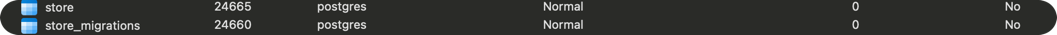

更新同一条数据

In [7]:
with PostgresStore.from_conn_string(DB_URL) as store:
    store.setup()
    store.put(namespace, user_id, {"name": "小红"})
    print(store.get(namespace, user_id))

Item(namespace=['users'], key='user-11', value={'name': '小红'}, created_at='2026-11-22T22:10:05.172007+08:00', updated_at='2026-11-22T22:11:13.458136+08:00')


可以看到， created_at 没变，但 updated_at 更改了。

### 2.2 search()：检索API

#### 2.2.1 search()源码

函数签名如下
```
def search(
        self,
        namespace_prefix: tuple[str, ...],
        /,
        *,
        query: str | None = None,
        filter: dict[str, Any] | None = None,
        limit: int = 10,
        offset: int = 0,
        refresh_ttl: bool | None = None,
    ) -> list[SearchItem]:
```
参数说明：
- namespace_prefix：命名空间前缀，在该前缀下搜索。
- query：语义检索时用于查询的自然语言。
- filter：过滤条件，value中的键值对组合，见下文举例。
- limit：可以返回item的最大条数，效果等同于SQL中的limit。
- offset：返回结果之前跳过的item数量。
- refresh_ttl：同上。

它支持两种检索方式（对应上面的参数2、3）：
- 按 filter 做结构化过滤 ，即用 value 中的 键值 筛选符合条件的记录。
- 按 query 做语义相似度检索 ，需要将输入转换为向量。

返回值：返回匹配的 SearchItem 列表，并额外携带匹配分数等检索元信息。

#### 2.2.2 举例1:按照namespace前缀检索

本节全部基于 InMemoryStore 测试。

In [8]:
from langgraph.store.memory import InMemoryStore

store = InMemoryStore()

namespace1 = ("users", "Alice", "memories")
key1 = 'preferences'
value1 = {
    "course": "计算机组成原理",
    "sports": "跑步",
    "food": "紫光园奶皮子酸奶"
}

namespace2 = ("users", "Bob", "memories")
key2 = 'preferences'
value2 = {
    "course": "数字电路与模拟电路",
    "sports": "跑步",
    "food": "奶皮子糖葫芦"
}

namespace3 = ("users", "Black", "memories")
key3 = 'preferences'
value3 = {
    "course": "数字电路与模拟电路",
    "sports": "羽毛球",
    "food": "紫光园奶皮子酸奶"
}

store.put(namespace1, key1, value1)
store.put(namespace2, key2, value2)
store.put(namespace3, key3, value3)

In [9]:
# 按照namespace前缀搜索

print('=' * 30, '-> (users, ) <-', "=" * 30)
for item in store.search(("users", )):
    print(item)

============================== -> (users, ) <- ==============================
Item(namespace=['users', 'Alice', 'memories'], key='preferences', value={'course': '计算机组成原理', 'sports': '跑步', 'food': '紫光园奶皮子酸奶'}, created_at='2026-11-22T14:17:50.863657+00:00', updated_at='2026-11-22T14:17:50.863660+00:00', score=None)
Item(namespace=['users', 'Bob', 'memories'], key='preferences', value={'course': '数字电路与模拟电路', 'sports': '跑步', 'food': '奶皮子糖葫芦'}, created_at='2026-11-22T14:17:50.863701+00:00', updated_at='2026-11-22T14:17:50.863702+00:00', score=None)
Item(namespace=['users', 'Black', 'memories'], key='preferences', value={'course': '数字电路与模拟电路', 'sports': '羽毛球', 'food': '紫光园奶皮子酸奶'}, created_at='2026-11-22T14:17:50.863730+00:00', updated_at='2026-11-22T14:17:50.863730+00:00', score=None)


In [10]:
print('=' * 30, '-> (users, Alice) <-', "=" * 30)
for item in store.search(("users", "Alice")):
    print(item)

============================== -> (users, Alice) <- ==============================
Item(namespace=['users', 'Alice', 'memories'], key='preferences', value={'course': '计算机组成原理', 'sports': '跑步', 'food': '紫光园奶皮子酸奶'}, created_at='2026-11-22T14:17:50.863657+00:00', updated_at='2026-11-22T14:17:50.863660+00:00', score=None)


#### 2.2.3 举例2:按照filter过滤

In [11]:
print("=" * 30, '-> (users, ), filter=food <-", "=" * 30)')
for item in store.search(("users", ), filter={"food": "紫光园奶皮子酸奶"}):
    print(item)

============================== -> (users, ), filter=food <-", "=" * 30)
Item(namespace=['users', 'Alice', 'memories'], key='preferences', value={'course': '计算机组成原理', 'sports': '跑步', 'food': '紫光园奶皮子酸奶'}, created_at='2026-11-22T14:17:50.863657+00:00', updated_at='2026-11-22T14:17:50.863660+00:00', score=None)
Item(namespace=['users', 'Black', 'memories'], key='preferences', value={'course': '数字电路与模拟电路', 'sports': '羽毛球', 'food': '紫光园奶皮子酸奶'}, created_at='2026-11-22T14:17:50.863730+00:00', updated_at='2026-11-22T14:17:50.863730+00:00', score=None)


In [14]:
print("=" * 30, '-> (users, ), filter=sports <-", "=" * 30)')
for item in store.search(("users", ), filter={"sports": "羽毛球"}):
    print(item)

============================== -> (users, ), filter=sports <-", "=" * 30)
Item(namespace=['users', 'Black', 'memories'], key='preferences', value={'course': '数字电路与模拟电路', 'sports': '羽毛球', 'food': '紫光园奶皮子酸奶'}, created_at='2026-11-22T14:17:50.863730+00:00', updated_at='2026-11-22T14:17:50.863730+00:00', score=None)


In [13]:
print("=" * 30, '-> (users, ), filter=course <-", "=" * 30)')
for item in store.search(("users", ), filter={"course": "数字电路与模拟电路"}):
    print(item)

============================== -> (users, ), filter=course <-", "=" * 30)
Item(namespace=['users', 'Bob', 'memories'], key='preferences', value={'course': '数字电路与模拟电路', 'sports': '跑步', 'food': '奶皮子糖葫芦'}, created_at='2026-11-22T14:17:50.863701+00:00', updated_at='2026-11-22T14:17:50.863702+00:00', score=None)
Item(namespace=['users', 'Black', 'memories'], key='preferences', value={'course': '数字电路与模拟电路', 'sports': '羽毛球', 'food': '紫光园奶皮子酸奶'}, created_at='2026-11-22T14:17:50.863730+00:00', updated_at='2026-11-22T14:17:50.863730+00:00', score=None)


#### 2.2.4 举例3:按照语义搜索

自定义嵌入函数，目的是查看嵌入向量。

In [15]:
from langgraph.store.memory import InMemoryStore

# 自定义嵌入函数
def embed(text: list[str]) -> list[list[float]]:
    return [[1.0] * 6 for _ in range(len(text))]

index_config = {
    "embed": embed,
    "dims": 6,
    "fields": ["$", "course"]
}

store = InMemoryStore(
    index = index_config
)

namespace1 = ("users", "Alice", "memories")
key1 = 'preferences'
value1 = {
    "course": "计算机组成原理",
    "sports": "跑步",
    "food": "紫光园奶皮子酸奶"
}

namespace2 = ("users", "Bob", "memories")
key2 = 'preferences'
value2 = {
    "course": "数字电路与模拟电路",
    "sports": "跑步",
    "food": "奶皮子糖葫芦"
}

namespace3 = ("users", "Black", "memories")
key3 = 'preferences'
value3 = {
    "course": "数字电路与模拟电路",
    "sports": "羽毛球",
    "food": "紫光园奶皮子酸奶"
}

store.put(namespace1, key1, value1)
store.put(namespace2, key2, value2)
store.put(namespace3, key3, value3)

初始化Store时通过index指定索引方式，后者源码如下
```
class IndexConfig(TypedDict, total=False):
    dims: int
    embed: Embeddings | EmbeddingsFunc | AEmbeddingsFunc | str
    fields: list[str] | None
```
- embeds ：将输入文本转换为向量的嵌入函数，可以是 自定义函数 ，也可以是 嵌入模型对象 ，本例传递的是自定义嵌入函数。
- dims ：输出向量维度
- fields ：用于计算向量的属性列表，这里的属性都是指value中的key，value是一个JSON-like字典，可取值如下
    - ["$"] ：将value作为整体嵌入
    - ["fileds1", "fields2"] ：单独指定某个一级字段
    - ["parent.child"] ：从内部的嵌套JSON对象中获取子字段的值
    - ["array[*].field"] ：从JSON数组的每个JSON对象中获取子字段的值
    - 注意：上述四种形式可以同时出现，fields列表的每个元素都会生成一个嵌入向量。

查看嵌入向量

In [16]:
from pprint import pprint
pprint(store._vectors)

defaultdict(<function InMemoryStore.__init__.<locals>.<lambda> at 0x106ff11c0>,
            {('users', 'Alice', 'memories'): defaultdict(<class 'dict'>,
                                                         {'preferences': {'$': [1.0,
                                                                                1.0,
                                                                                1.0,
                                                                                1.0,
                                                                                1.0,
                                                                                1.0],
                                                                          'course': [1.0,
                                                                                     1.0,
                                                                                     1.0,
                                                                  

还可以通过指定namespace、key、index_config的fields中指定的字段名查看特定向量。

In [18]:
from pprint import pprint
pprint(store._vectors[('users', 'Alice', 'memories')]['preferences']['course'])

[1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


也可以使用嵌入模型，支持以下模型

ValueError: Provider 'deepseek' is not supported.
Supported providers and their required packages:
  - azure_ai: langchain-azure-ai.embeddings
  - azure_openai: langchain-openai
  - bedrock: langchain-aws
  - cohere: langchain-cohere
  - google_genai: langchain-google-genai
  - google_vertexai: langchain-google-vertexai
  - huggingface: langchain-huggingface
  - mistralai: langchain-mistralai
  - ollama: langchain-ollama
  - openai: langchain-openai

In [ ]:
from langchain.embeddings import init_embeddings
import os

from dotenv import load_dotenv

load_dotenv(override=True)

embedding_model = init_embeddings(
    model="deepseek:deepseek-v4-pro",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL")
)

index_config = {
    "embed": embedding_model,
    "dims": 3072,
    "fields": ["$"]
}

store = InMemoryStore(
    index = index_config
)

namespace1 = ("users", "Alice", "memories")
key1 = 'preferences'
value1 = {
    "course": "计算机组成原理",
    "sports": "跑步",
    "food": "紫光园奶皮子酸奶"
}

namespace2 = ("users", "Bob", "memories")
key2 = 'preferences'
value2 = {
    "course": "数字电路与模拟电路",
    "sports": "跑步",
    "food": "奶皮子糖葫芦"
}

namespace3 = ("users", "Black", "memories")
key3 = 'preferences'
value3 = {
    "course": "数字电路与模拟电路",
    "sports": "羽毛球",
    "food": "紫光园奶皮子酸奶"
}

store.put(namespace1, key1, value1)
store.put(namespace2, key2, value2)
store.put(namespace3, key3, value3)

注意：如果只是指定了 query ，返回的是所有 namespace 前缀满足要求的 item 。底层会按照向量相似度计算查询和候选的 score ，输出结果按照score 降序排列 。可以结合 limit 或 filter 限制数据条数。